# Анализ сервиса аренды самокатов GoFast и статистическая проверка бизнес-гипотез

**Автор:** Затула Денис Викторович  

## Бизнес-контекст и цели исследования

Сервис аренды самокатов GoFast работает по двум тарифным моделям: базовый тариф без абонентской платы (`free`) и платная подписка (`ultra`). Для оценки экономической эффективности подписки, планирования промоакций и управления износом парка самокатов требуется проанализировать поведение пользователей и проверить ключевые продуктовые гипотезы.

**План исследования:**

1. Загрузка и первичный аудит данных о пользователях, поездках и тарифах.
2. Предобработка данных: приведение форматов дат, очистка дубликатов, округление длительности поездок.
3. Исследовательский анализ данных (география, возрастная структура, распределение подписок и длительности поездок).
4. Объединение таблиц и расчет помесячной выручки по каждому пользователю.
5. Статистическая проверка продуктовых гипотез о длительности поездок, износе самокатов и выручке.
6. Вероятностное моделирование распределений длительности и дистанции поездок для оценки промо-механик и порогов доплат.

## Описание данных

Анализ выполняется на основе трех таблиц в директории `../datasets/`:

- **`users_go.csv`** — профили пользователей (`user_id`, `name`, `age`, `city`, `subscription_type`).
- **`rides_go.csv`** — журнал поездок (`user_id`, `distance` в метрах, `duration` в минутах, `date`).
- **`subscriptions_go.csv`** — параметры тарифных планов (`subscription_type`, `minute_price`, `start_ride_price`, `subscription_fee`).

## 1. Загрузка данных и первичный осмотр

In [1]:
import pandas as pd

### 1.1. Чтение исходных таблиц

In [2]:
df_users_go = pd.read_csv('../datasets/users_go.csv')
df_rides_go = pd.read_csv('../datasets/rides_go.csv')
df_subscriptions_go = pd.read_csv('../datasets/subscriptions_go.csv')

### 1.2. Проверка структуры и примеров записей

In [3]:
df_users_go.head()

,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra


In [4]:
df_rides_go.head()

,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28


In [5]:
df_subscriptions_go.head()

,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


### 1.3. Оценка объема таблиц

In [6]:
for df in [df_users_go, df_rides_go, df_subscriptions_go]:
    print(df.shape[0], end = ' ')

1565 18068 2 

## 2. Предобработка данных

### 2.1. Проверка типов данных таблицы поездок

In [7]:
df_rides_go.dtypes

user_id       int64
distance    float64
duration    float64
date            str
dtype: object

### 2.2. Приведение даты к типу datetime

In [8]:
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'])

### 2.3. Выделение месяца поездки

In [9]:
df_rides_go['month'] = df_rides_go['date'].dt.month

### 2.4. Аудит пропусков и дубликатов

In [10]:
missing = df_users_go.isna().sum().sum()
duplicates = df_users_go.duplicated().sum()
print(f'{missing} {duplicates}')

0 31


### 2.5. Очистка данных от пропусков и дубликатов

In [11]:
# Проверяем пропуски и дубликаты в каждой таблице и выполняем очистку
for name, frame in [('users_go', df_users_go), ('rides_go', df_rides_go), ('subscriptions_go', df_subscriptions_go)]:
    missing = frame.isna().sum().sum()
    duplicates = frame.duplicated().sum()
    print(f'{name}: пропусков = {missing}, дубликатов = {duplicates}')
    if missing > 0:
        frame.fillna(0, inplace=True)
    if duplicates > 0:
        frame.drop_duplicates(inplace=True)

users_go: пропусков = 0, дубликатов = 31
rides_go: пропусков = 0, дубликатов = 0
subscriptions_go: пропусков = 0, дубликатов = 0


/tmp/ipykernel_4351/3698327859.py:9: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  frame.drop_duplicates(inplace=True)


### 2.6. Округление длительности поездок для тарификации

Округляем длительность поездок до целых минут и приводим к целочисленному типу в соответствии с правилами биллинга.

In [12]:
df_rides_go['duration'] = df_rides_go['duration'].round(0).astype(int)
df_rides_go.info()

<class 'pandas.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   user_id   18068 non-null  int64         
 1   distance  18068 non-null  float64       
 2   duration  18068 non-null  int64         
 3   date      18068 non-null  datetime64[us]
 4   month     18068 non-null  int32         
dtypes: datetime64[us](1), float64(1), int32(1), int64(2)
memory usage: 635.3 KB


## 3. Исследовательский анализ данных (EDA)

In [13]:
import matplotlib.pyplot as plt

### 3.1. География пользователей по городам

In [14]:
users_by_city_count = df_users_go['city'].value_counts()
users_by_city_count

city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64

### 3.2. Распределение пользователей по типам подписки

In [15]:
subscription_type_count = df_users_go['subscription_type'].value_counts()
subscription_type_count

subscription_type
free     835
ultra    699
Name: count, dtype: int64

### 3.3. Соотношение тарифов `free` и `ultra`

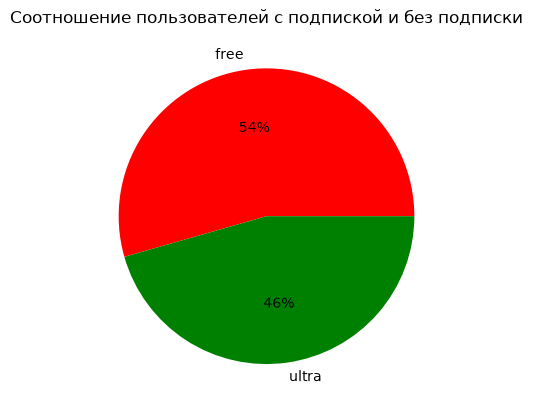

In [16]:
subscription_type_count.plot(
    kind='pie' ,
    title='Соотношение пользователей с подпиской и без подписки',
    autopct='%.0f%%' ,
    ylabel='' ,
    colors=['red', 'green']
)

plt.show()

### 3.4. Возрастное распределение пользователей

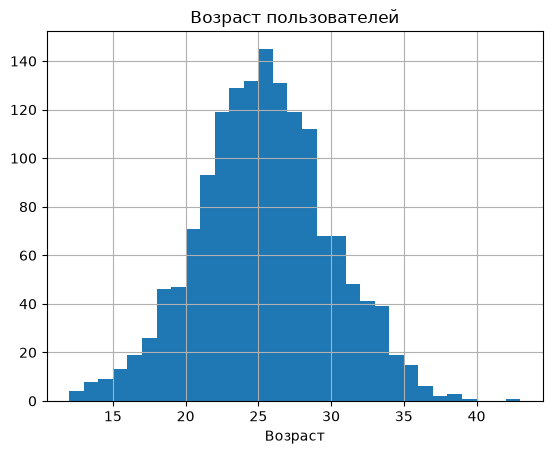

In [17]:
n_bins = df_users_go['age'].max() - df_users_go['age'].min()
df_users_go['age'].hist(bins = n_bins)
plt.title('Возраст пользователей')
plt.xlabel('Возраст')
plt.show()

### 3.5. Доля несовершеннолетних пользователей

In [18]:
users_under_18_ratio = round(100 * df_users_go[df_users_go['age'] < 18].shape[0] / df_users_go['age'].shape[0])
print(f'Доля несовершеннолетних пользователей самокатов составляет {users_under_18_ratio}%.')

Доля несовершеннолетних пользователей самокатов составляет 5%.


### 3.6. Описательные статистики длительности поездок

In [19]:
duration_mean = round(df_rides_go['duration'].mean())
duration_std = round(df_rides_go['duration'].std())

duration_pct25 = round(df_rides_go['duration'].quantile(0.25))
duration_pct75 = round(df_rides_go['duration'].quantile(0.75))

print(f'Средняя длительность поездки {duration_mean} минут со стандартным отклонением {duration_std}. Основная часть поездок занимает от {duration_pct25} до {duration_pct75} минут.')

Средняя длительность поездки 18 минут со стандартным отклонением 6. Основная часть поездок занимает от 14 до 22 минут.


## 4. Объединение данных и сегментация по подписке

### 4.1. Объединение профилей пользователей с журналом поездок

In [20]:
df = df_users_go.merge(df_rides_go, how = 'left', on = 'user_id')
df.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8


### 4.2. Присоединение справочника тарифов

In [21]:
df = df.merge(df_subscriptions_go, how = 'left', on = 'subscription_type')
df.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8,6,0,199


### 4.3. Проверка размерности объединенной витрины

In [22]:
# Выводим первые строки датафрейма
display(df.head())

# Выводим количество строк и столбцов в объединённом датафрейме
n_rows, n_cols = df.shape[0], df.shape[1]
print(f'В полученном датафрейме {n_rows} строк и {n_cols} столбцов.')

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8,6,0,199


В полученном датафрейме 18068 строк и 12 столбцов.


### 4.4. Выделение сегментов пользователей с подпиской (`ultra`) и без (`free`)

In [23]:
df_ultra = df[df['subscription_type'] == 'ultra']
df_free = df[df['subscription_type'] == 'free']
display(df_ultra.head())
df_free.head()

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8,6,0,199


,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
6500,700,Айдар,22,Омск,free,2515.690719,15,2021-01-02,1,8,50,0
6501,700,Айдар,22,Омск,free,846.932642,16,2021-02-01,2,8,50,0
6502,700,Айдар,22,Омск,free,4004.434142,20,2021-02-04,2,8,50,0
6503,700,Айдар,22,Омск,free,1205.911290,10,2021-02-10,2,8,50,0
6504,700,Айдар,22,Омск,free,3047.379435,17,2021-02-14,2,8,50,0


### 4.5. Сравнение распределения длительности поездок по тарифам

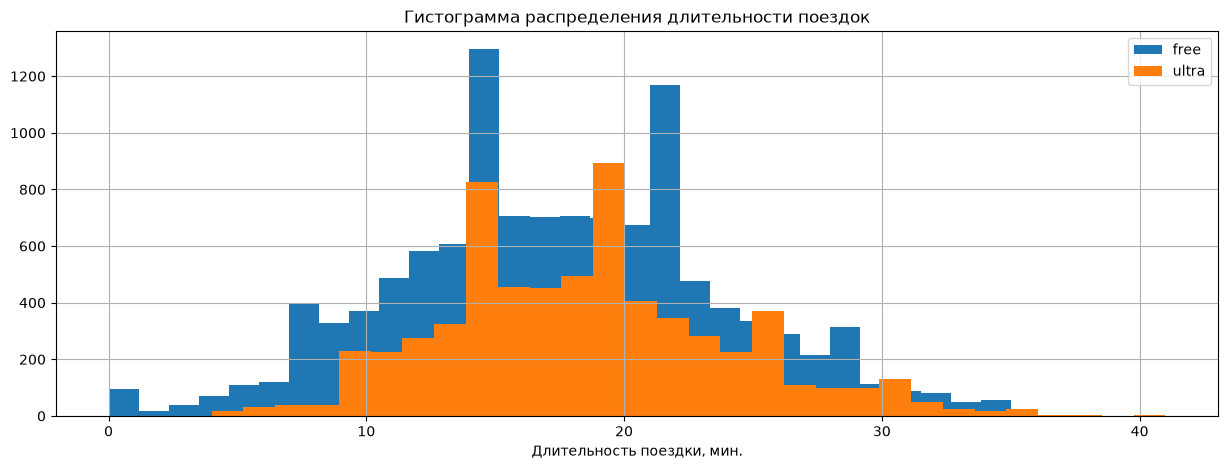

Средняя длительность поездки для пользователей без подписки 17 мин, а для пользователей с подпиской 19 мин


In [24]:
# Гистограмма длительности поездки для пользователей с подпиской и без
plt.figure(figsize=(15, 5))
df_free['duration'].hist(bins=30, label='free')
df_ultra['duration'].hist(bins=30, label='ultra')
plt.xlabel('Длительность поездки, мин.')
plt.title('Гистограмма распределения длительности поездок')
plt.legend()
plt.show()

# Расчет и вывод на экран средней длительности поездки для пользователей с подпиской и без
mean_duration_free = round(df_free['duration'].mean())
mean_duration_ultra = round(df_ultra['duration'].mean())
print(f'Средняя длительность поездки для пользователей без подписки {mean_duration_free} мин, а для пользователей с подпиской {mean_duration_ultra} мин')

## 5. Расчет помесячной выручки по пользователям

### 5.1. Группировка поездок по пользователям и месяцам

In [25]:
df_gp = df.groupby(
    ['user_id', 'name', 'subscription_type', 'month'], 
    as_index=False)
df_gp

### 5.2. Агрегация дистанции, длительности, числа поездок и параметров тарифа

In [26]:
df_agg = df_gp.agg(
    total_distance=('distance', 'sum'),
    total_duration=('duration', 'sum') ,
    rides_count=('duration', 'count') ,
    subscription_type=('subscription_type', 'first') ,
    minute_price=('minute_price', 'first') ,
    start_ride_price=('start_ride_price', 'first') ,
    subscription_fee=('subscription_fee', 'first') ,
)

### 5.3. Расчет месячной выручки на пользователя

Формула расчета: `monthly_revenue = start_ride_price * rides_count + minute_price * total_duration + subscription_fee`.

In [27]:
def calculate_monthly_revenue(row):
    """
    Рассчитывает месячную выручку на основе строки агрегированного датафрейма.

    Формула:
    monthly_revenue = start_ride_price * rides_count + minute_price * total_duration + subscription_fee

    Параметры
    ----------
    row : pd.Series
        Строка датафрейма с колонками start_ride_price, rides_count, minute_price,
        total_duration, subscription_fee.

    Возвращает
    -------
    float
        Месячная выручка от пользователя.
    """
    return row['start_ride_price'] * row['rides_count'] + row['minute_price'] * row['total_duration'] + row['subscription_fee']

### 5.4. Применение расчета выручки к агрегированной витрине

In [28]:
df_agg['monthly_revenue'] = df_agg.apply(calculate_monthly_revenue, axis = 1)

### 5.5. Профиль пользователя с максимальной суммарной выручкой

In [29]:
total_revenue_by_user = df_agg.groupby('user_id')['monthly_revenue'].sum()
top_ravenue_user = total_revenue_by_user.idxmax()
df_agg[df_agg['user_id'] == top_ravenue_user][['user_id', 'name', 'month', 'rides_count', 'monthly_revenue']]

,user_id,name,month,rides_count,monthly_revenue
8877,1236,Александр,1,2,228
8878,1236,Александр,2,3,614
8879,1236,Александр,3,5,762
8880,1236,Александр,4,1,202
8881,1236,Александр,5,3,574
8882,1236,Александр,6,1,282
8883,1236,Александр,7,1,290
8884,1236,Александр,8,2,452
8885,1236,Александр,9,1,122
8886,1236,Александр,10,3,430


## 6. Статистическая проверка бизнес-гипотез

In [30]:
import scipy.stats as st

### 6.1. Вспомогательная функция интерпретации p-value

In [31]:
def print_stattest_results(p_value: float, alpha: float = 0.05):
    """
    Интерпретирует результат статистического теста по значению p-value.

    Параметры
    ----------
    p_value : float
        Значение p-value, полученное в результате статистического теста.
    alpha : float, optional
        Уровень значимости (порог принятия решения), по умолчанию 0.05.

    Возвращает
    -------
    None
        Функция только печатает текстовый вывод, не возвращает значений.
    """
    if p_value < alpha:
        print(f'Полученное значение p_value={p_value} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.')
    else:
        print(f'Полученное значение p_value={p_value} больше критического уровня alpha={alpha}. Опровергнуть нулевую гипотезу нельзя.')
        
print_stattest_results(p_value=0.0001)
print_stattest_results(p_value=0.1)

Полученное значение p_value=0.0001 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Полученное значение p_value=0.1 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


### 6.2. Гипотеза 1: длительность поездок подписчиков `ultra` и пользователей `free`

- **H0:** средняя длительность поездки у подписчиков `ultra` и пользователей `free` одинакова.
- **H1:** средняя длительность поездки у подписчиков `ultra` выше, чем у пользователей `free`.
- **Уровень значимости:** `alpha = 0.05` (односторонний двухвыборочный t-тест).

In [32]:
ultra_duration = df_ultra['duration'].values
free_duration = df_free['duration'].values

results = st.ttest_ind(ultra_duration, free_duration, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)
ultra_mean_duration = ultra_duration.mean().round(2)
free_mean_duration = free_duration.mean().round(2)


print(f'Средняя длительность поездки тарифа Ultra {ultra_mean_duration}')
print(f'Средняя длительность поездки тарифа Free {free_mean_duration}')

Полученное значение p_value=3.160068943561195e-35 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя длительность поездки тарифа Ultra 18.55
Средняя длительность поездки тарифа Free 17.39


### 6.3. Гипотеза 2: соответствие средней дистанции подписчиков оптимальному порогу износа (3 130 м)

- **H0:** средняя дистанция поездки подписчиков `ultra` равна 3 130 м.
- **H1:** средняя дистанция поездки подписчиков `ultra` превышает 3 130 м.
- **Уровень значимости:** `alpha = 0.05` (односторонний одновыборочный t-тест).

In [33]:
null_hypothesis = 3130
ultra_distance = df_ultra['distance']

results = st.ttest_1samp(ultra_distance, null_hypothesis, alternative = 'greater')
p_value = results.pvalue
print_stattest_results(p_value)

Полученное значение p_value=0.9195368847849785 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


### 6.4. Гипотеза 3: помесячная выручка от подписчиков `ultra` и пользователей `free`

- **H0:** средняя месячная выручка от пользователей с подпиской `ultra` и без подписки `free` одинакова.
- **H1:** средняя месячная выручка от подписчиков `ultra` выше, чем от пользователей `free`.
- **Уровень значимости:** `alpha = 0.05` (односторонний двухвыборочный t-тест).

In [34]:
revenue_ultra = df_agg[df_agg['subscription_type'] == 'ultra']['monthly_revenue']
revenue_free = df_agg[df_agg['subscription_type'] == 'free']['monthly_revenue']

results = st.ttest_ind(revenue_ultra, revenue_free, alternative ='greater')
p_value = results.pvalue
print_stattest_results(p_value)

mean_revenue_ultra = round(revenue_ultra.mean())
mean_revenue_free = round(revenue_free.mean())

print(f'Средняя выручка подписчиков Ultra {mean_revenue_ultra} руб')
print(f'Средняя выручка подписчиков Free {mean_revenue_free} руб')

Полученное значение p_value=1.7274069878387872e-37 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя выручка подписчиков Ultra 359 руб
Средняя выручка подписчиков Free 322 руб


## 7. Вероятностное моделирование распределений поездок

Для оценки потенциального охвата промоакций и определения порога дополнительной платы за износ самокатов моделируем длительность и дистанцию поездок нормальным распределением по выборочным параметрам (`mu`, `sigma`).

### 7.1. Оценка параметров распределения длительности поездок подписчиков `ultra`

In [35]:
# Вычисляем среднее значение
mu = df_ultra['duration'].mean()

# Вычисляем стандартное отклонение
sigma = df_ultra['duration'].std()

# Задаём целевое время
target_time = 30

# Делаем вывод
print(f'Средняя длительность поездки {round(mu, 1)}, стандартное отклонение {round(sigma, 1)}.')

Средняя длительность поездки 18.5, стандартное отклонение 5.6.


### 7.2. Оценка доли поездок длительностью более 30 минут (CDF)

In [36]:
# Вычисляем вероятность того, что случайная величина будет меньше указанного значения или равна ему

duration_norm_dist  = st.norm(mu, sigma)
prob = round(1 - duration_norm_dist.cdf(target_time),3) # Используем CDF для нахождения накопленной вероятности

print(f'Вероятность поездки более 30 минут {prob}')

Вероятность поездки более 30 минут 0.02


### 7.3. Оценка доли поездок в интервале от 20 до 30 минут (CDF)

In [37]:
# Определяем границы интервала
low = 20
high = 30

# Вычисляем вероятность попадания в интервал
prob_interval = round(duration_norm_dist.cdf(high) - duration_norm_dist.cdf(low), 3)


# Выводим результат
print(f'Вероятность того, что пользователь совершит поездку длительностью от {low} до {high} минут: {prob_interval}')

Вероятность того, что пользователь совершит поездку длительностью от 20 до 30 минут: 0.377


### 7.4. Расчет критической дистанции для 90-го процентиля поездок (PPF)

Определяем порог дистанции, ниже которого укладывается 90% всех поездок сервиса (превышается в 10% случаев).

In [38]:
# Вычисляем среднее значение
mu = df['distance'].mean()

# Вычисляем стандартное отклонение
sigma = df['distance'].std()

# Вероятность, для которой хотим найти значение (90% случаев)
target_prob = 0.90

# Создаём объект нормального распределения
distance_norm = st.norm(mu, sigma)

# Рассчитываем критическую дистанцию для заданного процентиля поездок
critical_distance = distance_norm.ppf(target_prob)

print(f'{100 * target_prob} % поездок имеют дистанцию ниже критического значения {critical_distance:.2f} М.')

90.0 % поездок имеют дистанцию ниже критического значения 4501.94 М.


## 8. Итоговые выводы и рекомендации

### Ключевые результаты исследования

- **Аудитория и тарифы:** после удаления дубликатов база включает 1 534 уникальных пользователя из 8 городов (лидеры — Пятигорск, Екатеринбург, Ростов-на-Дону). Подпиской `ultra` пользуются 46% аудитории, базовым тарифом `free` — 54%. Доля несовершеннолетних пользователей составляет 5%.
- **Длительность поездок:** в среднем поездка длится 18 минут (основная часть — от 14 до 22 минут). Подписчики `ultra` ездят статистически значимо дольше пользователей `free` (18,55 мин против 17,39 мин; `p-value < 0,05`).
- **Износ самокатов:** гипотеза о превышении оптимальной дистанции 3 130 м среди подписчиков `ultra` не подтвердилась (`p-value > 0,05`), что свидетельствует о приемлемой нагрузке на парк.
- **Экономика подписки:** подписчики `ultra` приносят статистически значимо более высокую среднюю месячную выручку — 359 руб. против 322 руб. у пользователей `free` (`p-value < 0,05`).
- **Моделирование промо и доплат:** поездки подписчиков свыше 30 минут составляют всего 2% (низкий охват для промо), тогда как интервал 20–30 минут охватывает 37,7% поездок. Критическая дистанция (90-й процентиль по всем поездкам) составляет 4 501,94 м.

### Рекомендации для бизнеса

1. **Продвижение подписки `ultra`:** стимулировать переход пользователей `free` на платную подписку, так как подписчики генерируют более высокую среднемесячную выручку без избыточного износа техники.
2. **Настройка промоакций:** при запуске акций для удержания подписчиков ориентироваться на целевой диапазон длительности 20–30 минут (37,7% поездок) вместо порога > 30 минут (2%).
3. **Управление износом парка:** использовать порог 4 500 м как ориентир для тарификации сверхурочных дистанций (верхние 10% самых длительных поездок).